In [1]:
# Logistic Regression for Binary Classification
# Dataset: Breast Cancer Wisconsin Diagnostic Dataset

# Step 1: Import the required libraries
import pandas as pd
import numpy as np

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


In [3]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

In [4]:
# Step 2: Load the dataset
cancer = load_breast_cancer()

X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

In [5]:
# Original target: 0 = malignant, 1 = benign
# Convert to: 0 = malignant, 1 = benign
y = cancer.target

print("Dataset:")
print(X.head())

Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0  

In [6]:
print("\nDataset Shape:", X.shape)
print("\nTarget Classes:")
print("0 = Malignant")
print("1 = Benign")


Dataset Shape: (569, 30)

Target Classes:
0 = Malignant
1 = Benign


In [7]:
# Step 3: Separate input and output
print("\nInput Features:")
print(X.columns.tolist())


Input Features:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [8]:
print("\nOutput Variable: Diagnosis")

# Step 4: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)


Output Variable: Diagnosis


In [9]:
print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

# Step 5: Build and train the Logistic Regression model
# Scaling helps Logistic Regression handle different feature ranges
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)



Training Samples: 398
Testing Samples: 171


In [10]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [11]:
# Step 6: Predict the test results
y_pred = model.predict(X_test)

In [13]:
print("\nActual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred)



Actual Values:
[0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 1 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]

Predicted Values:
[0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]


In [14]:
# Step 7: Calculate accuracy
print("\nAccuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.9883040935672515


In [15]:
# Step 8: Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)



Confusion Matrix:
[[ 63   1]
 [  1 106]]


In [16]:
# Step 9: Calculate evaluation metrics
print("\nPrecision:", precision_score(
    y_test, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))

print("F1-Score:", f1_score(
    y_test, y_pred, zero_division=0
))


Precision: 0.9906542056074766
Recall: 0.9906542056074766
F1-Score: 0.9906542056074766


In [17]:
# Step 10: Predict the class of a new sample
new_sample = X.iloc[[0]]
new_prediction = model.predict(new_sample)[0]

print("\nPrediction for a New Sample:")
print("Class:", new_prediction)
print("Diagnosis:", cancer.target_names[new_prediction])


Prediction for a New Sample:
Class: 0
Diagnosis: malignant


In [20]:
print("if graph representation is needed we can use this code for this experiment")

if graph representation is needed we can use this code for this experiment


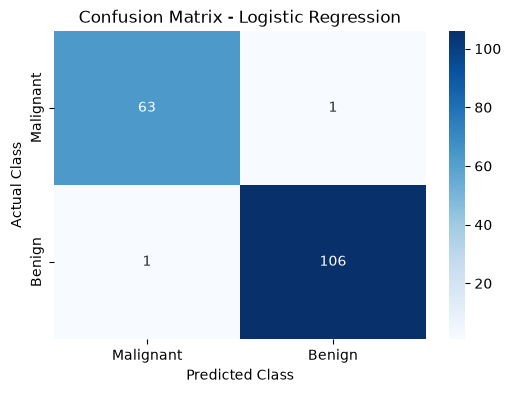

In [18]:
# Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Set the figure size
plt.figure(figsize=(6, 4))

# Display the confusion matrix as a heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

# Add labels to the X-axis and Y-axis
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Add the graph title
plt.title("Confusion Matrix - Logistic Regression")

# Display the graph
plt.show()

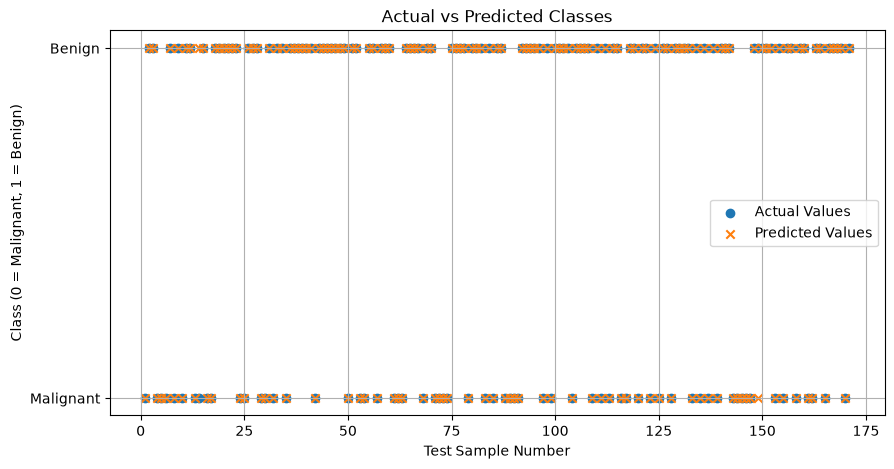

In [19]:
# Import required libraries
import matplotlib.pyplot as plt
import numpy as np

# Generate test sample numbers
sample_numbers = np.arange(1, len(y_test) + 1)

# Set the figure size
plt.figure(figsize=(10, 5))

# Plot the actual class values
plt.scatter(sample_numbers, y_test, label="Actual Values", marker="o")

# Plot the predicted class values
plt.scatter(sample_numbers, y_pred, label="Predicted Values", marker="x")

# Add labels to the axes
plt.xlabel("Test Sample Number")
plt.ylabel("Class (0 = Malignant, 1 = Benign)")

# Add the graph title
plt.title("Actual vs Predicted Classes")

# Set the class labels on the Y-axis
plt.yticks([0, 1], ["Malignant", "Benign"])

# Display the legend and grid
plt.legend()
plt.grid(True)

# Display the graph
plt.show()